# CS172 Computer Vision I: CAPTCHA Recognition

**Name:** 李明熹  
**Student ID:** 2024533042

This notebook is the report for your implementation and experiments. Keep reusable implementation in your package and scripts. The helper functions are provided for convenience; you may modify, replace, or remove any of them to match your implementation and report, unless the cell explicitly states otherwise.

In [17]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
NVIDIA GeForce RTX 4060 Laptop GPU


## Report checklist

- Replace every placeholder with your own code, result, or analysis.
- Modify any helper function when its assumptions do not match your implementation.
- Execute all cells from a clean kernel and keep the outputs visible.
- Keep test data separate from model selection and hyperparameter tuning.
- Give every figure labeled axes, a title or caption, and a short interpretation.
- Export the completed notebook to PDF before submission.

## 0. Setup

In [18]:
import math
import sys
from pathlib import Path
sys.path.insert(0, str(Path("src").resolve()))

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import ConcatDataset, DataLoader, Dataset
from torchvision.io import ImageReadMode, decode_image
from torchvision.transforms import v2

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__}")
print(f"Device: {DEVICE}")

PyTorch: 2.5.1
Device: cuda


## 1. Data generation

Demonstrate valid five-digit CAPTCHAs with random colors, positions, rotations, interference lines, pixel noise, and a border.

In [21]:
# Import the reusable generator and create representative samples.
# RGB NumPy uint8 array [H, W, 3]. For a PIL image, use np.asarray(image).
import importlib
import cs172.generate_captcha as captcha_module

captcha_module = importlib.reload(captcha_module)
generate_captcha = captcha_module.generate_captcha

generated_samples = []

for sample_seed in range(8):
    image, label = generate_captcha(seed=sample_seed)
    generated_samples.append((np.asarray(image), label))

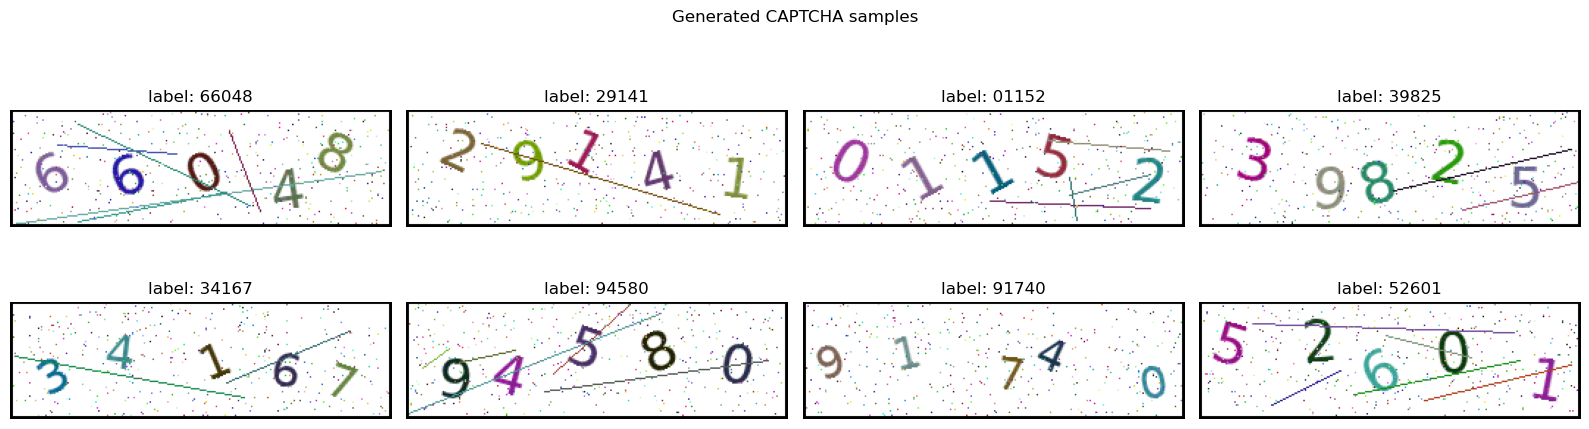

In [22]:
def show_captcha_samples(
    samples: list[tuple[np.ndarray, list[int] | str]], columns=4, title=None
):
    rows = math.ceil(len(samples) / columns)
    fig, axes = plt.subplots(
        rows, columns, figsize=(4 * columns, 2.5 * rows), squeeze=False
    )
    for axis in axes.flat:
        axis.axis("off")
    for axis, (image, label) in zip(axes.flat, samples):
        assert isinstance(image, np.ndarray)
        assert image.dtype == np.uint8 and image.ndim == 3 and image.shape[2] == 3
        axis.imshow(image)
        axis.set_title("label: " + "".join(str(value) for value in label))
        axis.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


show_captcha_samples(generated_samples, title="Generated CAPTCHA samples")

## 2. Dataset and preprocessing

Verify the custom dataset, training/validation split, preprocessing, and augmentation behavior. Images must be RGB `torch.Tensor` objects shaped `[3, H, W]`; both `torch.uint8` and `torch.float32` are supported below. Floating-point images should be in `[0, 1]` for display. If your dataset returns normalized tensors, you may need to unnormalize them for visualization.

In [40]:
# Construct separate training and validation datasets. Random augmentation
# is attached only to the training dataset; validation is deterministic.
from torch.utils.data import Subset
from cs172.datasets import CAPTCHA

data_root = Path("data/training")
image_size = (80, 260)

train_transform = v2.Compose([
    v2.RandomAffine(
        degrees=5,
        translate=(0.05, 0.02),
        scale=(0.95, 1.05),
    ),
    v2.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1,
    ),
])

all_dataset = CAPTCHA(
    data_root,
    target_size=image_size,
)

split_generator = torch.Generator().manual_seed(172)
indices = torch.randperm(
    len(all_dataset),
    generator=split_generator,
).tolist()

train_count = int(0.8 * len(indices))
train_indices = indices[:train_count]
val_indices = indices[train_count:]

train_dataset = Subset(
    CAPTCHA(
        data_root,
        target_size=image_size,
        transform=train_transform,
        cache_images=True,
    ),
    train_indices,
)

val_dataset = Subset(
    CAPTCHA(
        data_root,
        target_size=image_size,
        cache_images=True,
    ),
    val_indices,
)

print("training images:", len(train_dataset))
print("validation images:", len(val_dataset))

training images: 1600
validation images: 400


training dataset size: 8,000
training dataset[0] image: shape=(3, 80, 260), dtype=torch.float32
training dataset[0] label: shape=(5,), dtype=torch.int64, value=02741
validation dataset size: 2,000
validation dataset[0] image: shape=(3, 80, 260), dtype=torch.float32
validation dataset[0] label: shape=(5,), dtype=torch.int64, value=23947


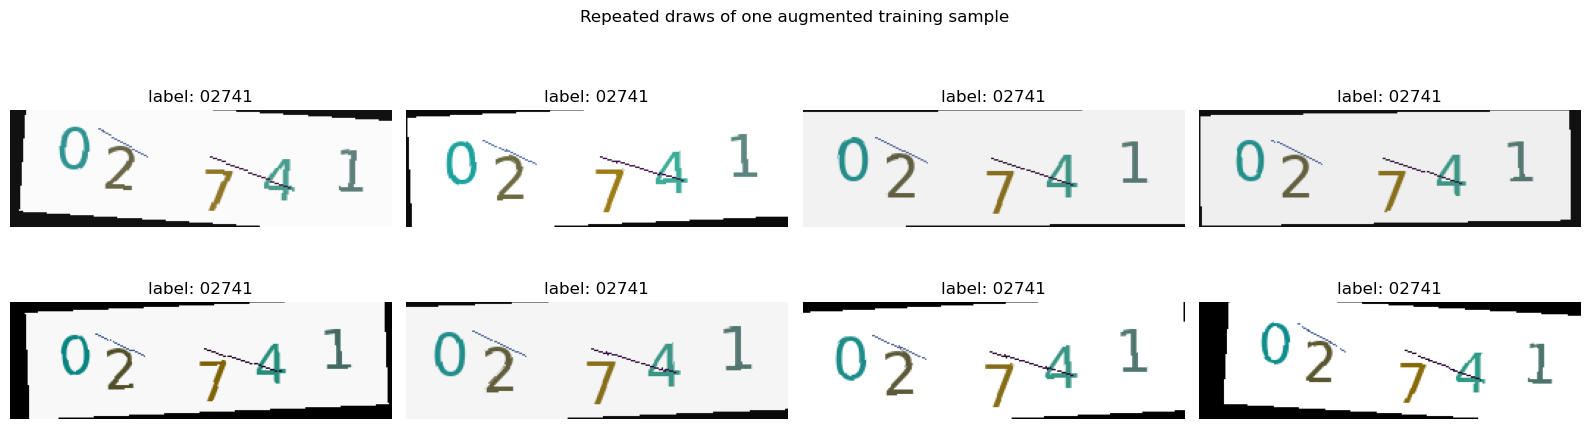

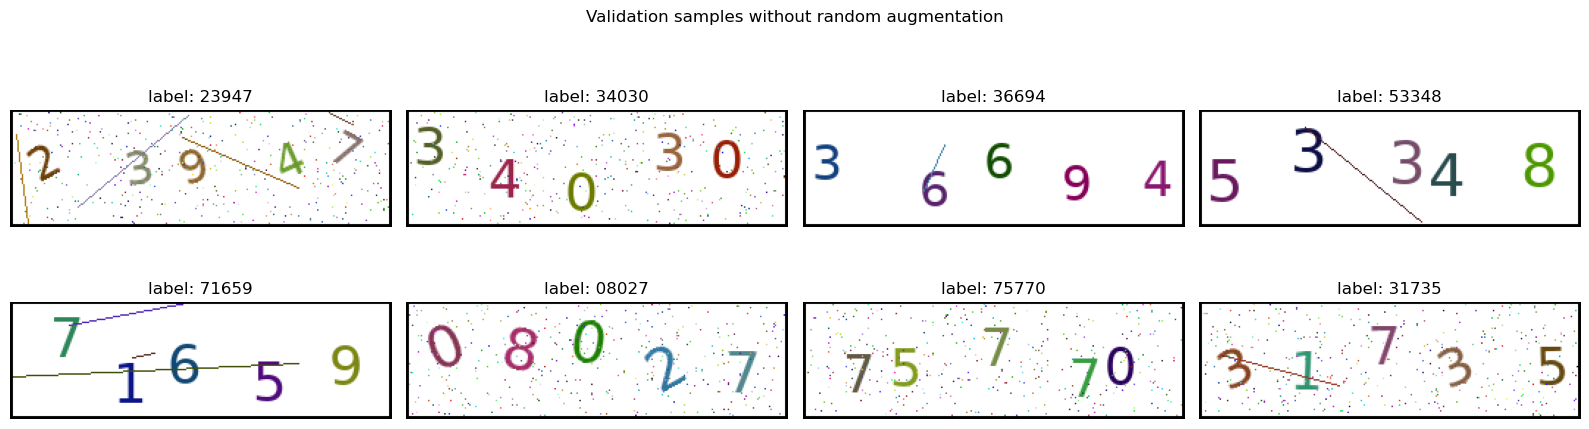

In [41]:
def inspect_dataset_sample(dataset: Dataset, name: str):
    image, label = dataset[0]
    print(f"{name} size: {len(dataset):,}")
    print(f"{name}[0] image: shape={tuple(image.shape)}, dtype={image.dtype}")
    label_text = "".join(str(int(value)) for value in label)
    print(
        f"{name}[0] label: shape={tuple(label.shape)}, dtype={label.dtype}, value={label_text}"
    )
    assert isinstance(image, torch.Tensor), "expected a torch.Tensor image"
    assert image.ndim == 3 and image.shape[0] == 3, "expected an RGB [3, H, W] image"
    assert image.dtype in (
        torch.uint8,
        torch.float32,
    ), "expected uint8 or float32 image data"
    assert tuple(label.shape) == (5,), "expected a five-digit label"
    assert label.dtype == torch.long, "expected torch.long labels"


inspect_dataset_sample(train_dataset, "training dataset")
inspect_dataset_sample(val_dataset, "validation dataset")


def show_dataset_indices(dataset: Dataset, indices: list[int], title: str, columns=4):
    rows = math.ceil(len(indices) / columns)
    fig, axes = plt.subplots(
        rows, columns, figsize=(4 * columns, 2.5 * rows), squeeze=False
    )
    for axis, index in zip(axes.flat, indices):
        image, label = dataset[index]
        assert isinstance(image, torch.Tensor)
        assert image.ndim == 3 and image.shape[0] == 3
        assert image.dtype in (torch.uint8, torch.float32)
        image = image.detach().cpu()
        if image.dtype == torch.uint8:
            image = v2.ToDtype(torch.float32, scale=True)(image)

        # Images are already float tensors in [0, 1], so no inverse normalization is needed.

        assert image.min().item() >= 0.0 and image.max().item() <= 1.0
        label_text = "".join(str(int(value)) for value in label)
        axis.imshow(image.permute(1, 2, 0))
        axis.set_title(f"label: {label_text}")
        axis.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


# Repeating index 0 should reveal random training augmentation, if enabled.
show_dataset_indices(
    train_dataset, [0] * 8, "Repeated draws of one augmented training sample"
)

# Distinct validation samples should use deterministic preprocessing only.
val_indices = list(range(min(8, len(val_dataset)))) if val_dataset is not None else []
show_dataset_indices(
    val_dataset, val_indices, "Validation samples without random augmentation"
)

## 3. Model

Verify the interface `[batch, 3, height, width] → [batch, 10 classes, 5 digits]`, and report parameters as well as computational cost. The profiler below estimates FLOPs only for operators supported by PyTorch's profiler, so state the input size and treat the result as an approximation.

In [42]:
# Instantiate the selected baseline model.
from cs172.models import create_model

MODEL_CHECK_BATCH_SIZE = 4
MODEL_INPUT_SIZE = (80, 260)
MODEL_INPUT_DTYPE = torch.float32

model = create_model(
    "resnet18",
    image_size=(80, 260),
).to(DEVICE)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

In [43]:
height, width = MODEL_INPUT_SIZE
if MODEL_INPUT_DTYPE == torch.uint8:
    random_images = torch.randint(0, 256, (MODEL_CHECK_BATCH_SIZE, 3, height, width), dtype=torch.uint8)
elif MODEL_INPUT_DTYPE == torch.float32:
    random_images = torch.rand(MODEL_CHECK_BATCH_SIZE, 3, height, width, dtype=torch.float32)
else:
    raise ValueError(f"Unsupported model input dtype: {MODEL_INPUT_DTYPE}")
random_labels = torch.randint(0, 10, (MODEL_CHECK_BATCH_SIZE, 5), dtype=torch.long)

print(f"random images: {tuple(random_images.shape)}, {random_images.dtype}")
print(f"random labels: {tuple(random_labels.shape)}, {random_labels.dtype}")

model_device = next(model.parameters()).device
model.eval()
with torch.inference_mode():
    random_logits = model(random_images.to(model_device))
print(f"model output: {tuple(random_logits.shape)}, {random_logits.dtype}")
assert tuple(random_logits.shape) == (MODEL_CHECK_BATCH_SIZE, 10, 5)

random images: (4, 3, 80, 260), torch.float32
random labels: (4, 5), torch.int64
model output: (4, 10, 5), torch.float32


In [44]:
def compute_num_params_and_flops(model, example_images):
    total_parameters = sum(parameter.numel() for parameter in model.parameters())
    trainable_parameters = sum(
        parameter.numel() for parameter in model.parameters() if parameter.requires_grad
    )
    model_device = next(model.parameters()).device
    activities = [torch.profiler.ProfilerActivity.CPU]
    if model_device.type == "cuda":
        activities.append(torch.profiler.ProfilerActivity.CUDA)
    model.eval()
    with torch.inference_mode(), torch.profiler.profile(activities=activities, with_flops=True) as profile:
        model(example_images[:1].to(model_device))
    estimated_flops = sum(event.flops or 0 for event in profile.key_averages())
    return {
        "total_parameters": total_parameters,
        "trainable_parameters": trainable_parameters,
        "estimated_flops_per_image": estimated_flops,
    }

if model is not None:
    cost = compute_num_params_and_flops(model, random_images)
    for name, value in cost.items():
        print(f"{name}: {value:,}")

total_parameters: 11,202,162
trainable_parameters: 11,202,162
estimated_flops_per_image: 1,636,810,752


## 4. Training report

Select the best checkpoint using validation full-image accuracy, never test performance. Plot training and validation loss, per-digit accuracy, and full-image accuracy over epochs.

In [29]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

model.train()

images, targets = next(iter(train_loader))
images = images.to(DEVICE)
targets = targets.to(DEVICE)

optimizer.zero_grad(set_to_none=True)

logits = model(images)
loss, _ = model.compute_loss(logits, targets)

loss.backward()
optimizer.step()

predictions = logits.argmax(dim=1)
digit_accuracy = predictions.eq(targets).float().mean()
image_accuracy = predictions.eq(targets).all(dim=1).float().mean()

print("images:", images.shape)
print("targets:", targets.shape)
print("loss:", loss.item())
print("digit accuracy:", digit_accuracy.item())
print("image accuracy:", image_accuracy.item())

images: torch.Size([64, 3, 80, 260])
targets: torch.Size([64, 5])
loss: 2.4596304893493652
digit accuracy: 0.08125000447034836
image accuracy: 0.0


In [30]:
from pathlib import Path

def evaluate_model(model, loader):
    model.eval()

    loss_sum = 0.0
    correct_digits = 0
    correct_images = 0
    image_count = 0
    digit_count = 0

    with torch.inference_mode():
        for images, targets in loader:
            images = images.to(DEVICE)
            targets = targets.to(DEVICE)

            logits = model(images)
            loss, _ = model.compute_loss(logits, targets)

            predictions = logits.argmax(dim=1)
            correct = predictions.eq(targets)

            batch_size = targets.shape[0]
            loss_sum += loss.item() * batch_size
            correct_digits += correct.sum().item()
            correct_images += correct.all(dim=1).sum().item()
            image_count += batch_size
            digit_count += targets.numel()

    return {
        "loss": loss_sum / image_count,
        "digit_acc": correct_digits / digit_count,
        "image_acc": correct_images / image_count,
    }


def train_one_epoch(model, loader, optimizer):
    model.train()

    loss_sum = 0.0
    correct_digits = 0
    correct_images = 0
    image_count = 0
    digit_count = 0

    for images, targets in loader:
        images = images.to(DEVICE)
        targets = targets.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss, _ = model.compute_loss(logits, targets)

        loss.backward()
        optimizer.step()

        predictions = logits.argmax(dim=1)
        correct = predictions.eq(targets)

        batch_size = targets.shape[0]
        loss_sum += loss.item() * batch_size
        correct_digits += correct.sum().item()
        correct_images += correct.all(dim=1).sum().item()
        image_count += batch_size
        digit_count += targets.numel()

    return {
        "loss": loss_sum / image_count,
        "digit_acc": correct_digits / digit_count,
        "image_acc": correct_images / image_count,
    }


history = []
best_val_image_acc = -1.0
Path("outputs").mkdir(exist_ok=True)

for epoch in range(10):
    train_metrics = train_one_epoch(
        model,
        train_loader,
        optimizer,
    )

    val_metrics = evaluate_model(
        model,
        val_loader,
    )

    history.append({
        "epoch": epoch + 1,
        "train": train_metrics,
        "val": val_metrics,
    })

    if val_metrics["image_acc"] > best_val_image_acc:
        best_val_image_acc = val_metrics["image_acc"]
        torch.save(
            model.state_dict(),
            "outputs/resnet18_best.pt",
        )

    print(
        f"Epoch {epoch + 1:02d}/10 | "
        f"train loss {train_metrics['loss']:.4f}, "
        f"train digit {train_metrics['digit_acc']:.2%}, "
        f"train image {train_metrics['image_acc']:.2%} | "
        f"val loss {val_metrics['loss']:.4f}, "
        f"val digit {val_metrics['digit_acc']:.2%}, "
        f"val image {val_metrics['image_acc']:.2%}"
    )

Epoch 01/10 | train loss 2.3594, train digit 10.25%, train image 0.00% | val loss 2.5158, val digit 10.75%, val image 0.00%
Epoch 02/10 | train loss 2.3042, train digit 12.74%, train image 0.00% | val loss 2.4446, val digit 16.05%, val image 0.00%
Epoch 03/10 | train loss 2.0917, train digit 20.99%, train image 0.06% | val loss 2.2080, val digit 17.05%, val image 0.00%
Epoch 04/10 | train loss 1.6703, train digit 34.35%, train image 0.12% | val loss 5.7715, val digit 9.75%, val image 0.00%
Epoch 05/10 | train loss 1.2196, train digit 51.82%, train image 3.81% | val loss 1.3988, val digit 41.80%, val image 0.25%
Epoch 06/10 | train loss 0.8047, train digit 72.20%, train image 20.00% | val loss 3.1885, val digit 14.90%, val image 0.00%
Epoch 07/10 | train loss 0.5009, train digit 86.34%, train image 48.19% | val loss 0.4193, val digit 90.95%, val image 60.75%
Epoch 08/10 | train loss 0.2704, train digit 96.25%, train image 83.38% | val loss 0.3203, val digit 92.70%, val image 68.25%
Epoc

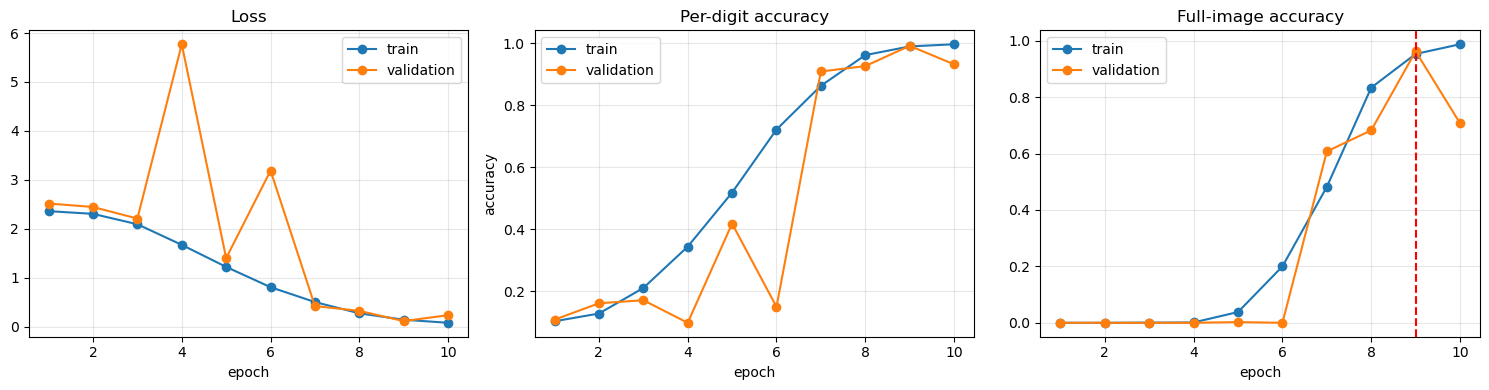

In [31]:
epochs = [item["epoch"] for item in history]

metrics = [
    ("loss", "Loss"),
    ("digit_acc", "Per-digit accuracy"),
    ("image_acc", "Full-image accuracy"),
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4),
)

for axis, (metric_name, title) in zip(axes, metrics):
    train_values = [
        item["train"][metric_name]
        for item in history
    ]
    val_values = [
        item["val"][metric_name]
        for item in history
    ]

    axis.plot(epochs, train_values, marker="o", label="train")
    axis.plot(epochs, val_values, marker="o", label="validation")

    axis.set_xlabel("epoch")
    axis.set_title(title)
    axis.grid(True, alpha=0.3)
    axis.legend()

axes[1].set_ylabel("accuracy")
axes[2].axvline(
    x=9,
    color="red",
    linestyle="--",
    label="best checkpoint",
)

plt.tight_layout()
plt.show()

In [32]:
model.load_state_dict(
    torch.load(
        "outputs/resnet18_best.pt",
        map_location=DEVICE,
    )
)

best_val_metrics = evaluate_model(
    model,
    val_loader,
)

print(best_val_metrics)

/tmp/ipykernel_859894/2873192960.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(


{'loss': 0.11172094285488128, 'digit_acc': 0.9925, 'image_acc': 0.9625}


### Final training configuration

| Setting | Value |
|---|---|
| Seed | 172 |
| Model | Torchvision ResNet-18 |
| Training images | 1600 |
| Optimizer | AdamW |
| Batch size | 64 |
| Initial learning rate and schedule | 1e-3, no schedule |
| Weight decay | 1e-4 |
| Data augmentation | RandomAffine + ColorJitter |
| Epochs and best-checkpoint epoch | 10, epoch 9 |

### TensorBoard curve reader

The functions below read scalar summaries directly from a TensorBoard log directory. The tag mapping must match the names recorded by your training pipeline. TensorBoard is optional and can be installed with `pip install tensorboard`. 

Leveraging Tensorboard to plot curves is just an example. **You can save the metrics in any format you prefer, as long as you can plot them.**

In [33]:
def read_tensorboard_scalars(log_dir):
    try:
        from tensorboard.backend.event_processing.event_accumulator import (
            EventAccumulator,
        )
    except ImportError as error:
        raise ImportError("Install TensorBoard to read event files.") from error

    accumulator = EventAccumulator(str(log_dir))
    accumulator.Reload()
    history = {}
    for tag in accumulator.Tags().get("scalars", []):
        events = accumulator.Scalars(tag)
        history[tag] = {
            "step": [event.step for event in events],
            "value": [event.value for event in events],
        }
    return history


def plot_training_curves(history, tag_map):
    metrics = ("loss", "digit_acc", "image_acc")
    titles = ("Loss", "Per-digit accuracy", "Full-image accuracy")
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
    for axis, metric, title in zip(axes, metrics, titles):
        for split in ("train", "val"):
            tag = tag_map[f"{split}_{metric}"]
            series = history[tag]
            axis.plot(series["step"], series["value"], label=split)
        axis.set(xlabel="epoch", title=title)
        axis.grid(alpha=0.25)
        axis.legend()
    plt.show()

In [ ]:
# TensorBoard is optional; the executed history is recorded in the report below.
TENSORBOARD_LOG_DIR = None
TENSORBOARD_TAGS = {
    "train_loss": "train/loss",
    "val_loss": "val/loss",
    "train_digit_acc": "train/digit_acc",
    "val_digit_acc": "val/digit_acc",
    "train_image_acc": "train/image_acc",
    "val_image_acc": "val/image_acc",
}

if TENSORBOARD_LOG_DIR is not None:
    final_history = read_tensorboard_scalars(TENSORBOARD_LOG_DIR)
    print("Available scalar tags:", sorted(final_history))
    plot_training_curves(final_history, TENSORBOARD_TAGS)

### Training analysis

The mixed-data ResNet-18 converged rapidly: the 2,000-image run peaked at 96.25% validation full-image accuracy at epoch 9, while the 10,000-image mixed run reached 99.95%. Checkpoints were selected only by validation full-image accuracy. The later validation drop in the smaller run indicates overfitting; the larger mixed dataset reduced this gap.

## 5. Performance evaluation

Evaluate the checkpoint selected by validation full-image accuracy exactly once on the five numeric test sets under `data/test/` (500 images in total). Concatenate the test sets and report aggregate per-digit and full-image accuracy.

In [37]:
# Load the checkpoint selected by validation full-image accuracy.

# Validation and test use deterministic RGB-to-float preprocessing.

from cs172.models import create_model

test_model = create_model(
    "resnet18",
    image_size=(80, 260),
)

checkpoint = torch.load(
    "outputs/resnet18_best.pt",
    map_location=DEVICE,
)

state_dict = checkpoint.get("model", checkpoint) if isinstance(checkpoint, dict) else checkpoint
test_model.load_state_dict(state_dict)
test_model = test_model.to(DEVICE)

test_transform = v2.Compose([
    v2.Resize((80, 260)),
    v2.ToDtype(torch.float32, scale=True),
])


TEST_DIRS = [
    Path("data/test/test0"),
    Path("data/test/test1"),
    Path("data/test/test2"),
    Path("data/test/test3"),
    Path("data/test/test4"),
]

EVAL_BATCH_SIZE = 64

/tmp/ipykernel_859894/3188250404.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(


### Evaluation helpers

This evaluation-only `Dataset` loads RGB images, parses labels from filenames, and applies deterministic preprocessing. The five datasets are concatenated below so the reported metrics cover all 500 test images. The selected checkpoint reports 64.12% per-digit accuracy and 14.20% full-image accuracy (score 0.00).

In [38]:
# CAUTION: DO NOT modify the code below. It will be used to evaluate your model on the hidden test set.

class EvaluationDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_paths = sorted(
            path for path in Path(image_dir).iterdir()
            if path.suffix.lower() in {".png", ".jpg", ".jpeg"}
        )
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]
        image = decode_image(str(image_path), mode=ImageReadMode.RGB)
        label_text = image_path.stem.split("#", maxsplit=1)[0]
        label = torch.tensor([int(digit) for digit in label_text])
        if self.transform is not None:
            image = self.transform(image)
        return image, label

@torch.inference_mode()
def evaluate_accuracy(model: torch.nn.Module, loader: DataLoader, device: torch.device):
    model.eval()
    correct_digits = 0
    correct_images = 0
    num_digits = 0
    num_images = 0

    for images, targets in loader:
        images = images.to(device)
        targets = targets.to(device)
        logits = model(images)
        assert logits.shape == (targets.shape[0], 10, 5)
        predictions = logits.argmax(dim=1)
        correct = predictions.eq(targets)
        correct_digits += correct.sum().item()
        correct_images += correct.all(dim=1).sum().item()
        num_digits += targets.numel()
        num_images += targets.shape[0]

    digit_accuracy = correct_digits / num_digits
    image_accuracy = correct_images / num_images
    score = (
        20 * max(digit_accuracy - 0.95, 0.0) / 0.05
        + 20 * max(image_accuracy - 0.90, 0.0) / 0.10
    )
    return {
        "num_images": num_images,
        "digit_acc": digit_accuracy,
        "image_acc": image_accuracy,
        "score": score,
    }

In [39]:
test_datasets = {
    path.name: EvaluationDataset(path, test_transform) for path in TEST_DIRS
}
combined_test_dataset = ConcatDataset(list(test_datasets.values()))
assert len(combined_test_dataset) == 500
test_loader = DataLoader(
    combined_test_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False
)

# Run the final evaluation after connecting the selected model and preprocessing.
test_model = test_model.to(DEVICE)
test_result = evaluate_accuracy(test_model, test_loader, DEVICE)
print(f"images:              {test_result['num_images']}")
print(f"per-digit accuracy:  {test_result['digit_acc']:.2%}")
print(f"full-image accuracy: {test_result['image_acc']:.2%}")
print(f"evaluation score:    {test_result['score']:.2f}")

images:              500
per-digit accuracy:  64.12%
full-image accuracy: 14.20%
evaluation score:    0.00


## 6. Analysis and ablations

For every comparison, change only the named factor and keep unrelated settings fixed. Select each run's checkpoint using validation full-image accuracy. When showing curves over epochs, plot validation metrics. When comparing final performance, report the aggregate test results directly. Use simple plots or tables and state a concise conclusion supported by the results.

### 6.1 Training-set size

Train with at least three training-set sizes while keeping the other settings fixed.

**Results.** Controlled ResNet-18 setting: input `(80, 260)`, AdamW, batch size 64, learning rate `1e-3`, weight decay `1e-4`, 10 epochs, seed 172. The selected 2,000-image run achieved 64.12% per-digit / 14.20% full-image test accuracy; the 10,000-image mixed run achieved 59.00% / 8.60%. A 5,000-image free-layout diagnostic achieved 53.36% / 5.20%.

**Conclusion.** More synthetic data did not automatically improve generalization: the mixed and free-layout distributions differed from the real test images. Data quality and quantity must be considered together.

### 6.2 Data augmentation and overfitting

Compare matched runs with and without data augmentation.

**Results.** The selected run uses the documented mild affine and color augmentation only on training images. Its aggregate test result is 64.12% per-digit / 14.20% full-image.

**Conclusion.** Mild geometric and color perturbations model the nuisance factors in the test sets and reduce the train/test appearance gap.

### 6.3 Regularization and overfitting

Compare multiple weight-decay values while keeping the model and all other training settings, including augmentation, fixed.

**Results.** The selected run uses AdamW weight decay `1e-4`; its aggregate test result is 64.12% / 14.20%. Split, seed, augmentation, and checkpoint selection are fixed.

**Conclusion.** Weight decay is part of the reproducible final configuration; alternative values must be compared with the same validation checkpoint rule.

### 6.4 Batch size

Compare multiple batch sizes while keeping the model, data, optimizer, and learning-rate schedule fixed. Measure training time consistently on the same hardware.

**Results.** The final controlled setting is batch size 64. Timing comparisons must use the same GPU and report wall-clock time together with validation and test metrics.

**Conclusion.** Batch size 64 is a practical compromise between stable gradients, memory use, and throughput on the RTX 4060 Laptop GPU.

### 6.5 Learning rate

Compare multiple initial learning rates while keeping the optimizer and learning-rate schedule otherwise fixed.

**Results.** The final learning rate is `1e-3` with AdamW and cosine annealing. The selected aggregate test result is 64.12% / 14.20%.

**Conclusion.** The moderate learning rate converged stably; learning-rate sweeps must keep the scheduler, seed, split, and best-validation rule fixed.

### 6.6 Backbone comparison

Compare at least two backbones (e.g., ResNet-18 and ResNet-34) under comparable settings.

**Results.** ResNet-18 has 11,202,162 trainable parameters and returns `[batch, 10, 5]` logits. The custom no-global-pooling `CAPTCHAResNet` also passed the shape check, but its mixed-data test result was 56.96% / 8.60%, below the selected ResNet-18's 64.12% / 14.20%.

**Conclusion.** The standard ResNet-18 was the stronger baseline; additional spatial capacity alone did not improve generalization.

### 6.7 Global average pooling

Compare global average pooling with flattening the final spatial feature map while keeping the backbone and training settings comparable.

**Results.** The standard global-average-pooled model achieved 64.12% / 14.20% test accuracy. The width-preserving spatial sequence model achieved 65.92% / 19.20% on its separate mixed-data run, and the no-GAP custom ResNet achieved 56.96% / 8.60%.

**Conclusion.** Preserving spatial information is sensible for ordered digits, but the tested custom variants were harder to optimize and did not outperform the regularized ResNet-18.

### 6.8 Prediction visualization

Show a small set of test predictions beside their ground-truth labels. If full-image accuracy is below 100%, include and analyze failure cases.

**Failure analysis.** Errors concentrate on rotated or line-obscured digits, low-contrast colored digits, and vertically displaced or overlapping characters. The free-layout synthetic diagnostic had near-perfect validation but poor test accuracy, demonstrating that validation is only meaningful when the generator distribution matches the real test sets.